# Sobol generated runs for WOMBATlite

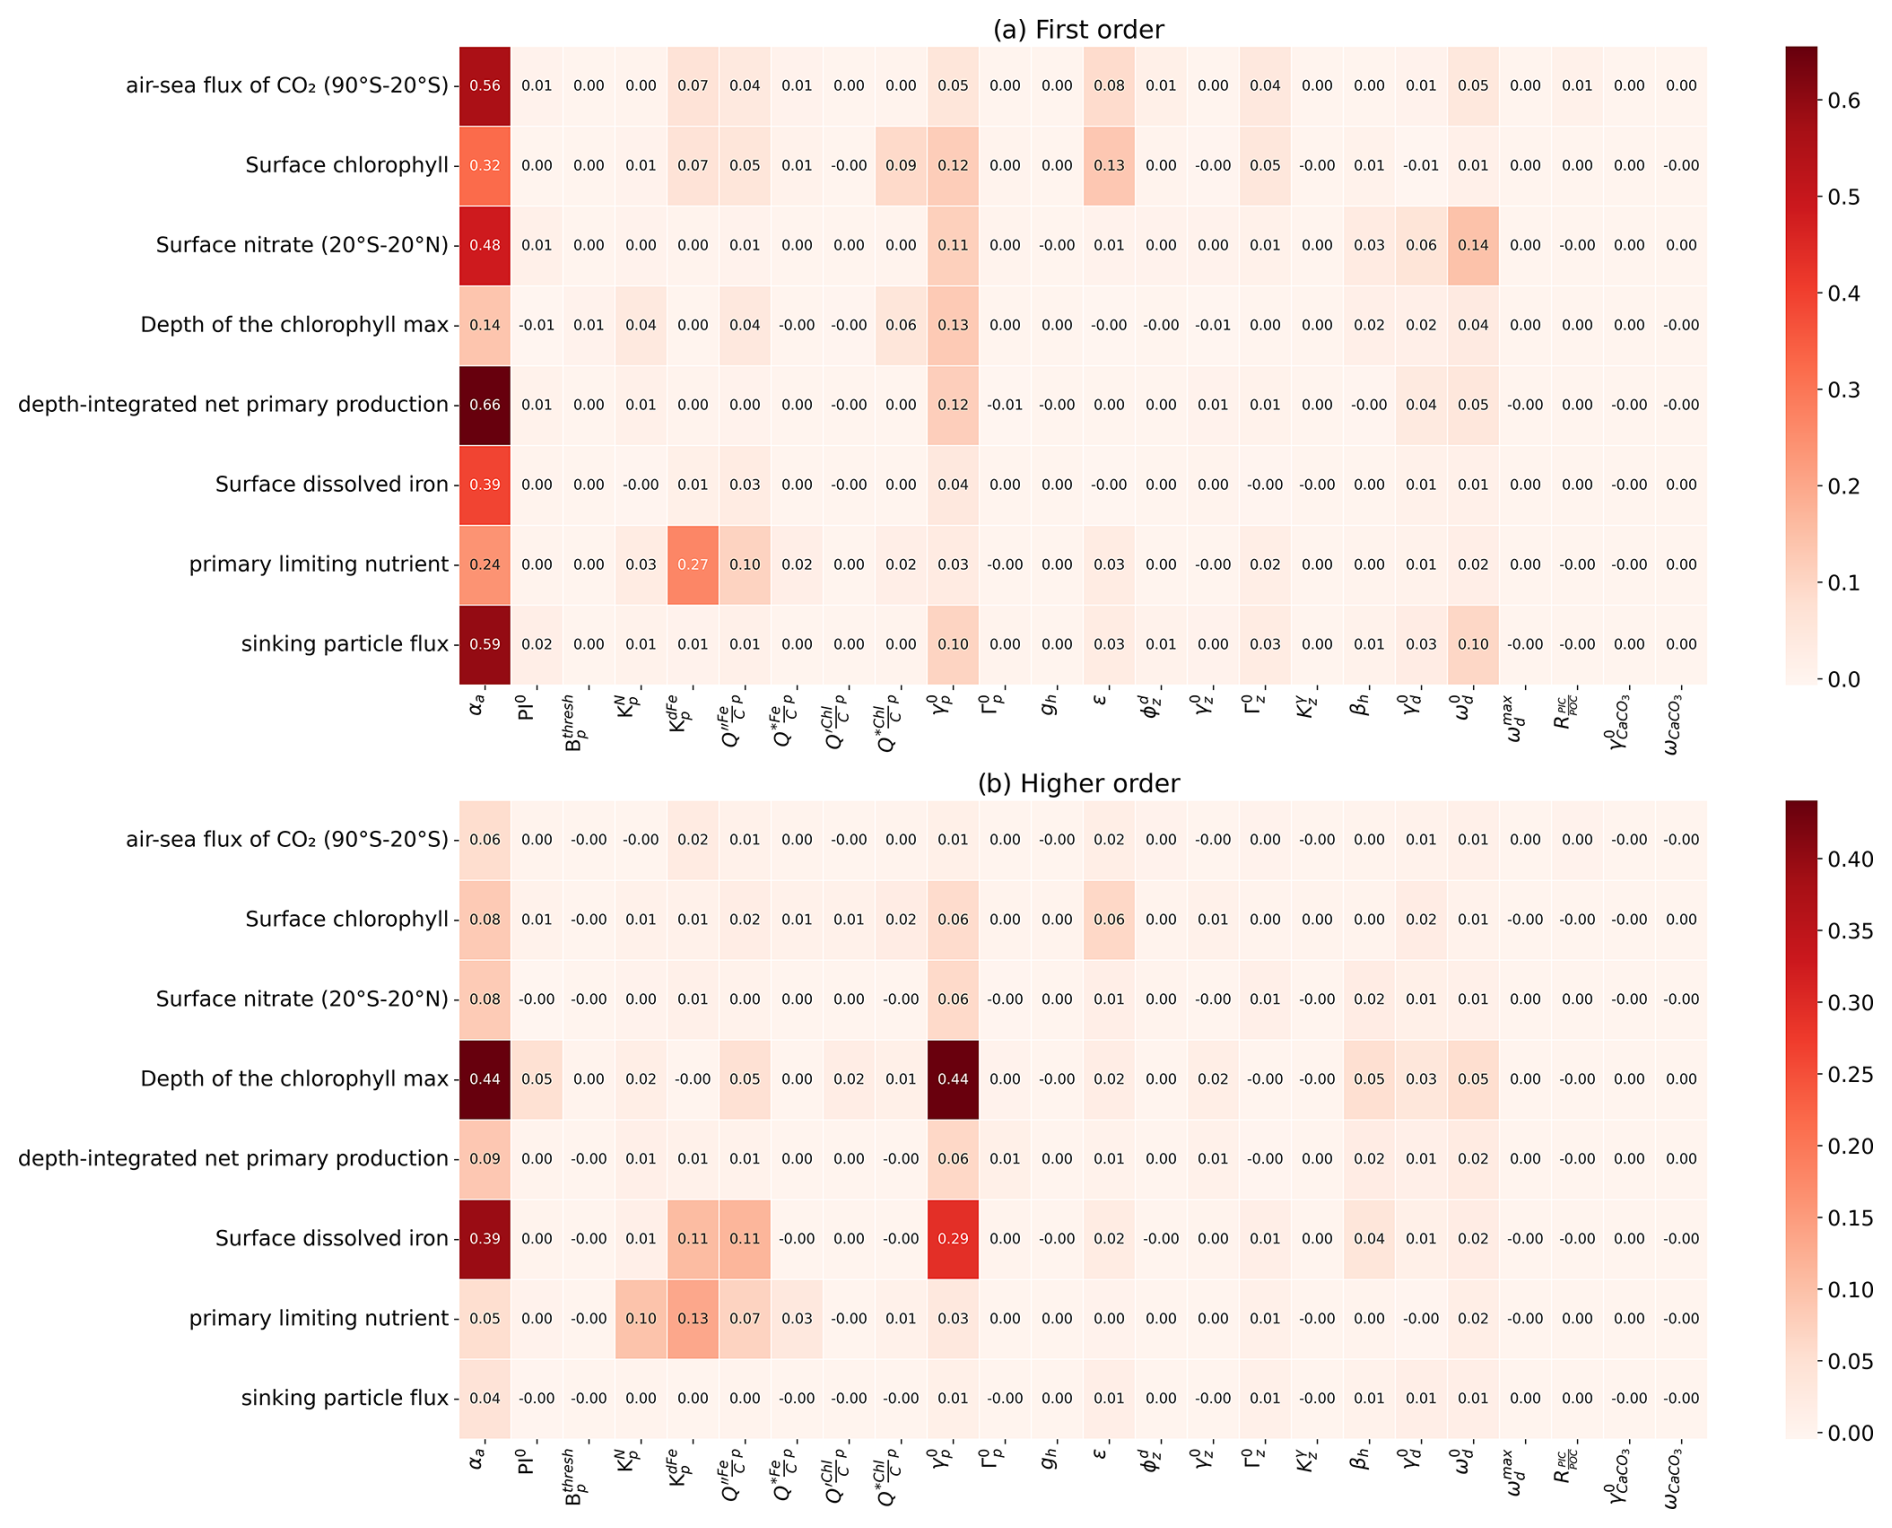

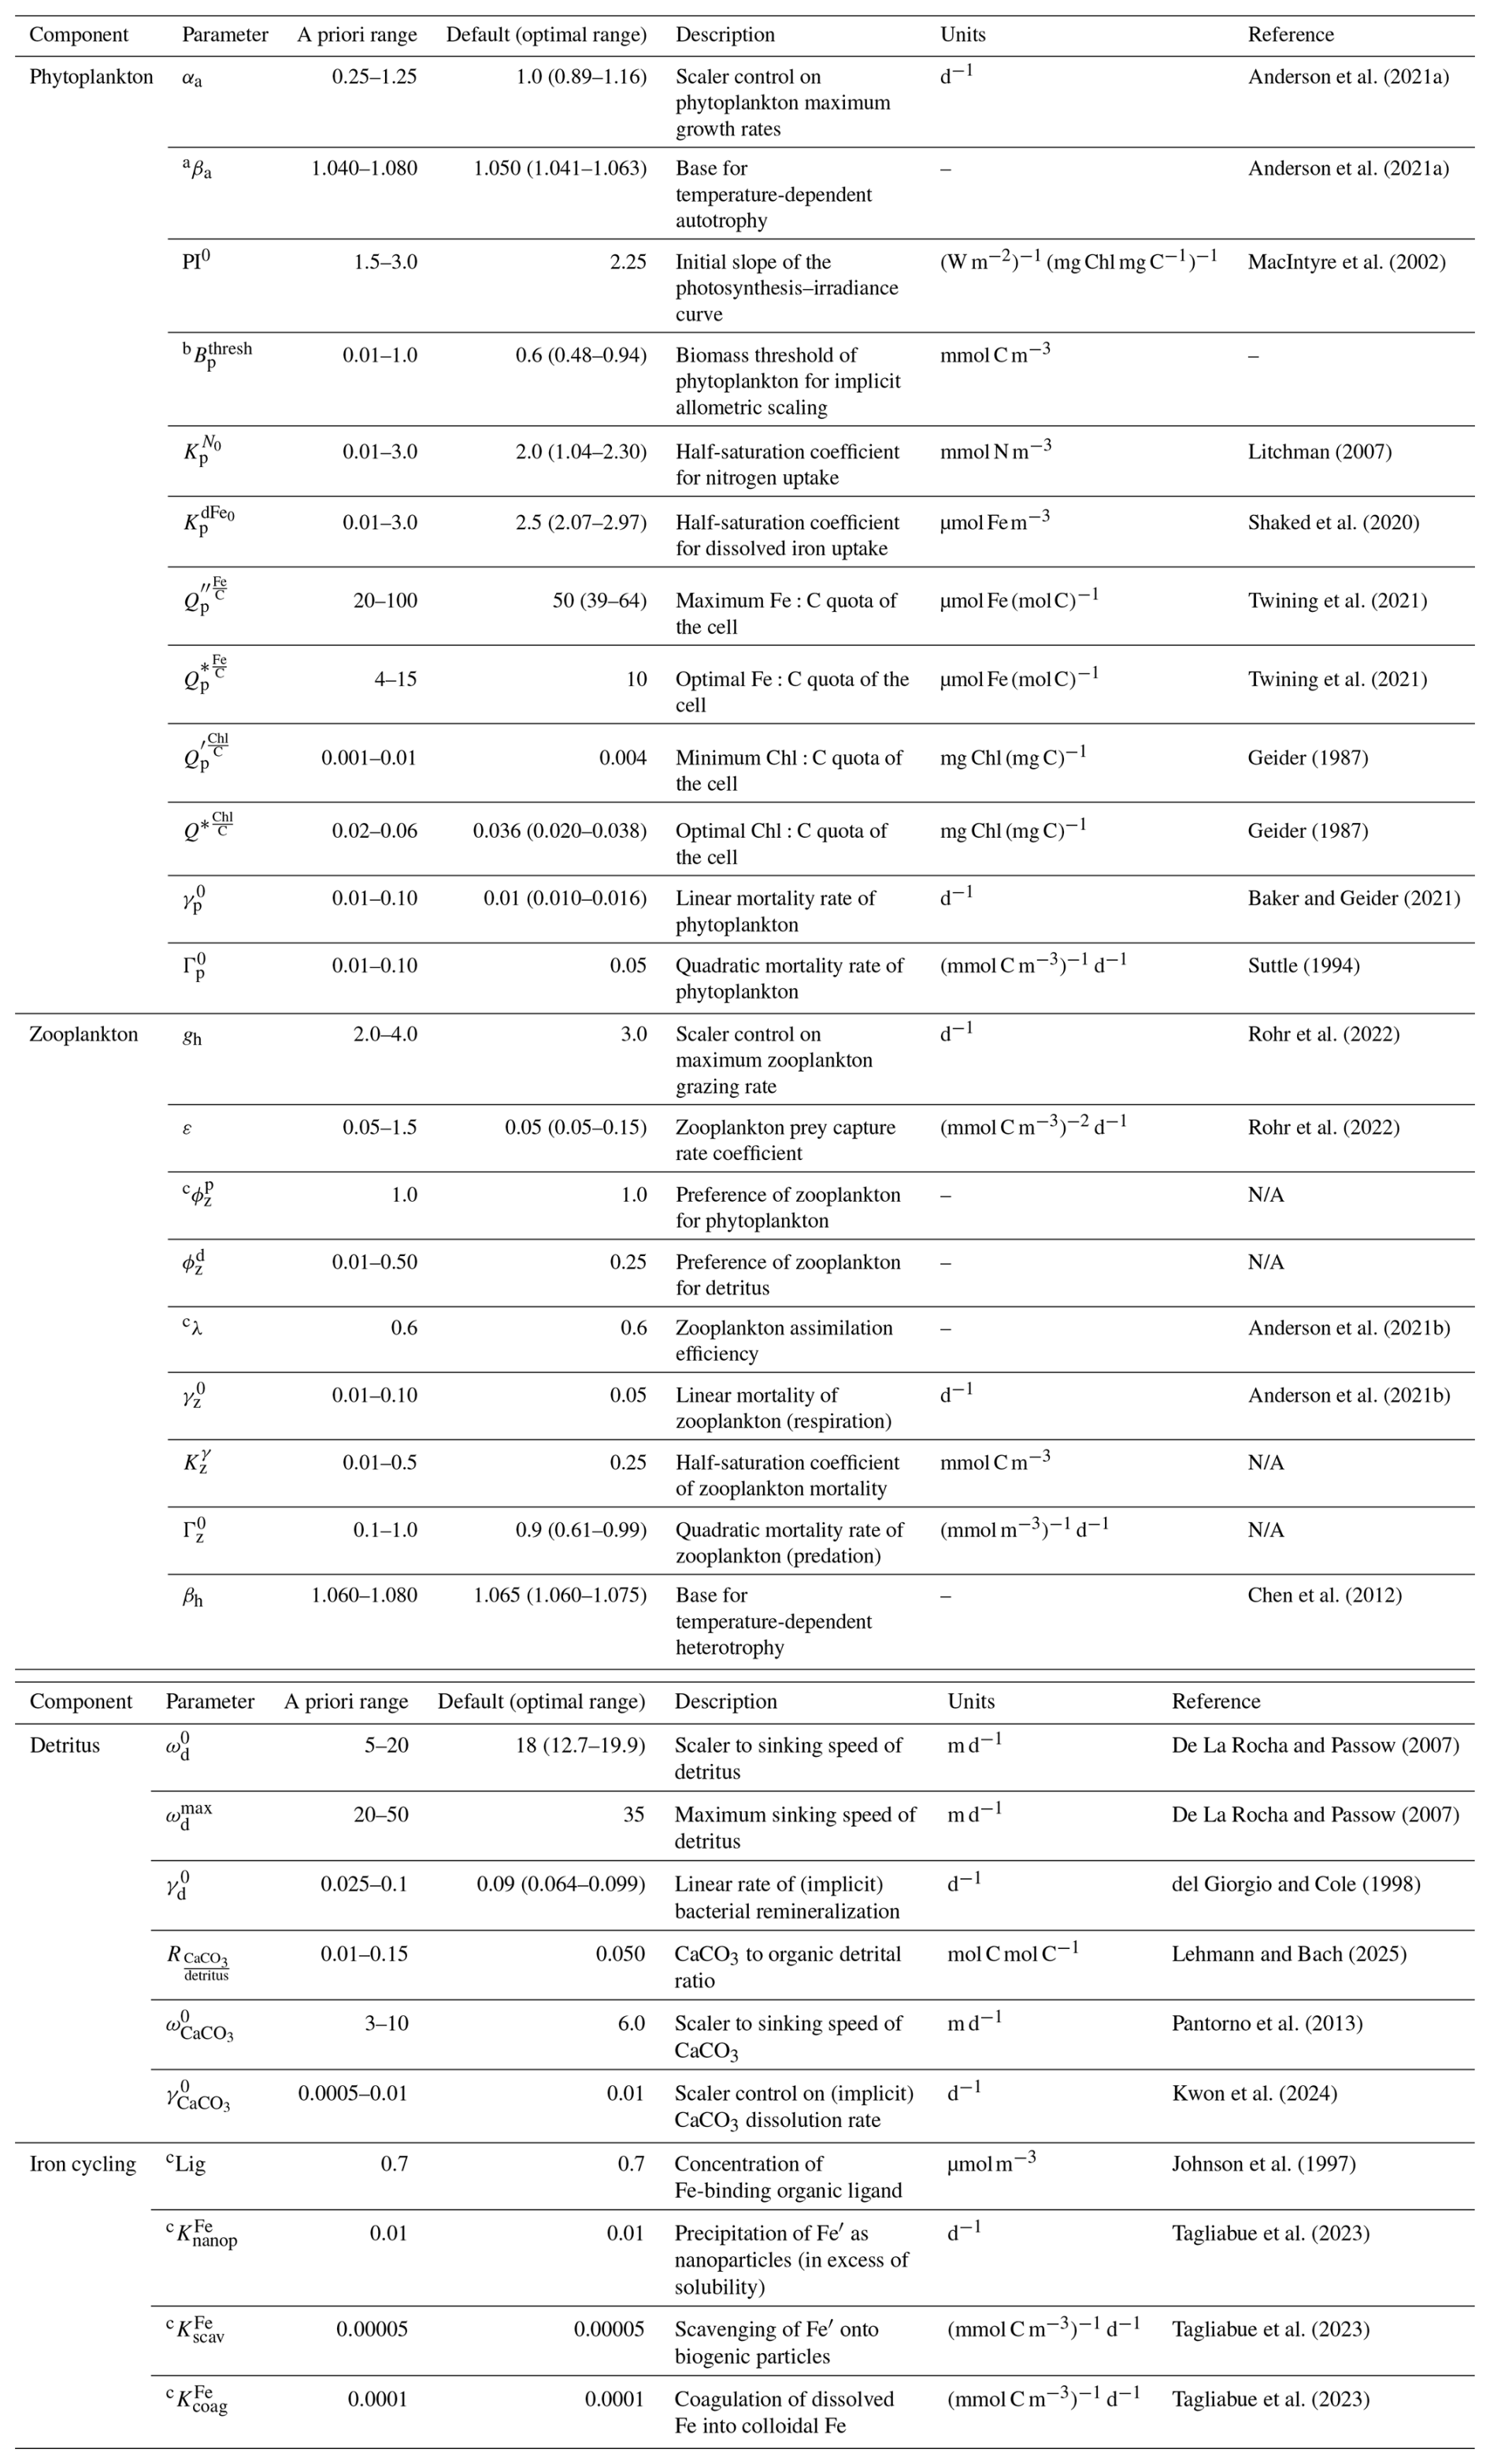

In [9]:
import numpy as np
import pandas as pd
from scipy.stats import qmc
import os
import matplotlib.pyplot as plt

# adjust path
path = '/g/data/jk72/ao2582/ACCESS/wombathy/wombatlite/'

bounds = {
    "phylmor": (0.002/86400, 0.004/86400),
     "abioa": (0.89/86400, 1.16/86400),
     "zooqmor": (0.61/86400, 0.99/86400)}


def generate_sobol_samples(bounds, m=8, seed=42):
    """
    Generate Sobol samples for an arbitrary number of parameters.
    Parameters
    ----------
    bounds : Dictionary of parameter bounds:
            {  "param1": (min, max),
            "param2": (min, max),}
    m : int, optional
        Number of Sobol levels.
        Number of samples = 2**m.

    seed : int, optional        Random seed for scrambling.
    """
    param_names = list(bounds.keys())
    bounds_array = np.array([bounds[p] for p in param_names], dtype=float)
    sampler = qmc.Sobol(d=len(param_names), scramble=True, seed=seed)
    u = sampler.random_base2(m=m)

    lower = bounds_array[:, 0]
    upper = bounds_array[:, 1]
    samples = lower + u * (upper - lower)

    return pd.DataFrame(samples, columns=param_names)

        phylmor     abioa   zooqmor
0  3.312568e-08  0.000013  0.000011
1  4.328272e-08  0.000012  0.000009
2  3.652582e-08  0.000012  0.000010
3  2.631635e-08  0.000011  0.000007
4  2.415265e-08  0.000013  0.000009
64


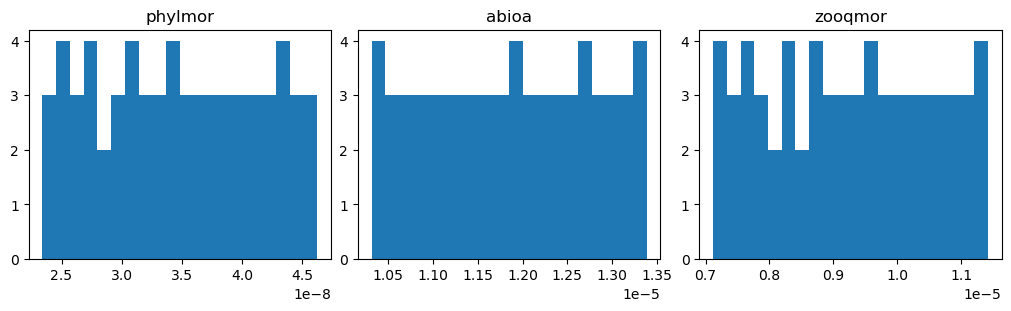

In [17]:
df = generate_sobol_samples(bounds, m=6)

print(df.head())
print(len(df))
inputs = list(df.keys())

# Distribbution of input parameter

fig, axes = plt.subplots(1, 3, figsize=(10, 3), constrained_layout=True)
axes = axes.flatten()

for i, col in enumerate(inputs):
    ax = axes[i]
    ax.hist(df[col], bins=20)
    ax.set_title(col)

plt.show()

In [18]:
with open(path+"sobol_run_lite.sh", "w") as f:

    f.write("#!/bin/bash\n\n")

    for i, row in df.iterrows():

        run_dir = f"lite_control_{i:04d}"

        cmd = f'./new_exp.sh "{run_dir}"'

        for param in df.columns:
            cmd += f' "{param}" "{row[param]:.10e}"'

        f.write(cmd + "\n")


# Write summary file
summary = df.copy()

# Insert experiment name as first column
summary.insert(0, "experiment",
               [f"lite_control_{i:04d}" for i in range(len(summary))])

summary.to_csv(path + "summary_file_lite.txt",
    sep="\t",   # tab separated
    index=False, float_format="%.10e")

print("Created:")
print("sobol_run_lite.sh")
print("summary_file_lite.txt")

Created:
sobol_run_lite.sh
summary_file_lite.txt


In [14]:
0.9/86400

1.0416666666666666e-05

## Process data after Sobol run

In [1]:
import xarray as xr
import pandas as pd
import glob
from dask import delayed, compute
import dask
import os
 

path = '/g/data/jk72/ao2582/ACCESS/wombathy/wombatlite/'
#print(glob.glob(current_dir + '*'))
summary_file = "summary_file_lite.txt"

df = pd.read_csv(path + summary_file, sep=r"\s+")
df = df.rename(columns={"experiment": "exp"})

exp_summary = (df.set_index("exp").to_dict(orient="index"))
    
    
path_data = '/g/data/jk72/ao2582/PyTorch/lite_data/'


from dask.distributed import Client
client = Client(n_workers=16, threads_per_worker=1)

2026-11-05 08:36:56,107 - distributed.nanny - WARNING - Restarting worker
2026-11-05 08:36:56,130 - distributed.nanny - WARNING - Restarting worker
2026-11-05 08:36:56,133 - distributed.nanny - WARNING - Restarting worker
2026-11-05 08:36:56,136 - distributed.nanny - WARNING - Restarting worker
2026-11-05 08:36:56,141 - distributed.nanny - WARNING - Restarting worker
2026-11-05 08:36:56,146 - distributed.nanny - WARNING - Restarting worker
2026-11-05 08:36:56,151 - distributed.nanny - WARNING - Restarting worker
2026-11-05 08:36:56,158 - distributed.nanny - WARNING - Restarting worker
2026-11-05 08:36:56,165 - distributed.nanny - WARNING - Restarting worker
2026-11-05 08:36:56,173 - distributed.nanny - WARNING - Restarting worker
2026-11-05 08:36:56,182 - distributed.nanny - WARNING - Restarting worker
2026-11-05 08:36:56,195 - distributed.nanny - WARNING - Restarting worker
2026-11-05 08:36:56,206 - distributed.nanny - WARNING - Restarting worker
2026-11-05 08:36:56,216 - distributed.

In [2]:
# Overview
print(list(exp_summary.keys()))

['lite_control_0000', 'lite_control_0001', 'lite_control_0002', 'lite_control_0003', 'lite_control_0004', 'lite_control_0005', 'lite_control_0006', 'lite_control_0007', 'lite_control_0008', 'lite_control_0009', 'lite_control_0010', 'lite_control_0011', 'lite_control_0012', 'lite_control_0013', 'lite_control_0014', 'lite_control_0015', 'lite_control_0016', 'lite_control_0017', 'lite_control_0018', 'lite_control_0019', 'lite_control_0020', 'lite_control_0021', 'lite_control_0022', 'lite_control_0023', 'lite_control_0024', 'lite_control_0025', 'lite_control_0026', 'lite_control_0027', 'lite_control_0028', 'lite_control_0029', 'lite_control_0030', 'lite_control_0031', 'lite_control_0032', 'lite_control_0033', 'lite_control_0034', 'lite_control_0035', 'lite_control_0036', 'lite_control_0037', 'lite_control_0038', 'lite_control_0039', 'lite_control_0040', 'lite_control_0041', 'lite_control_0042', 'lite_control_0043', 'lite_control_0044', 'lite_control_0045', 'lite_control_0046', 'lite_contro

In [3]:
params = ['thetao',  'phy','zoo','det','o2','fe','detremi','reminr', 'reminr_nn' ,'det_vmove','npp3d', 'pco2']

# --- Optimized file loading function ---
def open_om3_variable(path_exp, varname):
    pattern = f"{path_exp}/access-om3.mom6.*d.{varname}.1day.mean.*.nc"
    files = sorted(glob.glob(pattern))
   # print(files)
    if not files:
        raise FileNotFoundError(f"No files found for variable {varname}")

    ds = xr.open_mfdataset(
        files,
        combine="nested",
        concat_dim="time",
        data_vars="minimal",
        coords="minimal",
        compat="override",
        decode_times=False,
        #chunks={"time": 365},  # Enable chunking per year
        parallel=True  # Faster with many files
        )
    return ds

#import gc


#ds_all = []

# --- Delayed experiment loader ---
@delayed
def load_experiment(exp):
    print(f"Loading experiment: {exp}")
    try:
        # Get latest output directory
        path_exp_glob = sorted(glob.glob(os.path.join(path, exp, "archive", "output00*")))
        if not path_exp_glob:
            print(f"No output directory for {exp}")
            return None
        path_exp = path_exp_glob[-1]

        # Load all variables and merge
        ds_list = []
        for var in params:
            try:
                ds_var = open_om3_variable(path_exp, var)
                ds_list.append(ds_var)
                ds_var.close()
            except FileNotFoundError:
                print(f" Missing variable {var} in {exp}")

        if not ds_list:
            print(f"No data loaded for {exp}")
            return None

        # Merge variables (lazy)
        ds = xr.merge(ds_list, compat="override", join="override")
        
        # Fix time encoding
        ds = ds.assign_coords(time=ds.time)  # Ensure time is coordinate
        ds.time.attrs["units"] = "days since 0001-01-01 00:00:00"
        ds.time.attrs["calendar"] = "julian"
        ds = xr.decode_cf(ds, decode_timedelta=False)

        # Add experiment coordinates
        ds = ds.expand_dims(exp=[exp])  # Add exp dim early
        for pname, pval in exp_summary[exp].items():
            ds = ds.assign_coords({pname: ((), pval, {})})

        return ds

    except Exception as e:
        print(f"Error loading {exp}: {e}")
        return None

# --- Launch all tasks ---
tasks = [load_experiment(exp) for exp in exp_summary]

print("Computing all experiments (lazy loading)...")
results = compute(*tasks)


print('-- done')

Computing all experiments (lazy loading)...
-- done


In [5]:
# Filter out None results
valid_results = [r for r in results if r is not None]

# --- Concatenate all into one dataset ---
print("Concatenating all experiments...")
ds_all = xr.concat(valid_results, dim="exp", coords="different", combine_attrs="drop_conflicts", compat='equals')

# Optional: rechunk for better access
#ds_all = ds_all.chunk({"exp": 1, "time": 365})

ds = ds_all.mean(dim=['xh','yh']).drop_vars('time_bnds')   #.groupby('time.year')[3].groupby('time.month')[1 and 2].mean(dim='time')

print('-- done')

Concatenating all experiments...
-- done


In [ ]:
# --- Write to NetCDF ---
outfile = os.path.join(path_data, "sobol_WOMBATlite.nc")
print(f"Writing to {outfile}")
ds.to_netcdf(outfile)
print("-- DONE --")

#outfile = os.path.join(path_data, "test_all.nc")
#ds_all.to_zarr(outfile.replace(".nc", ".zarr"), mode="w")

#xr.open_zarr(...).to_netcdf(...)
#ds_all.close()
ds.close()

Writing to /g/data/jk72/ao2582/PyTorch/lite_data/sobol_WOMBATlite.nc


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 17.39 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [7]:
ds_lites =  xr.open_dataset(path_data +"sobol_WOMBATlite.nc", decode_timedelta=True )

Variables:
thetao               float32   float32
average_T1           datetime64[ns]   datetime64[ns]
average_T2           datetime64[ns]   datetime64[ns]
average_DT           float64   float64
phy                  float32   float32
zoo                  float32   float32
det                  float32   float32
o2                   float32   float32
fe                   float32   float32
detremi              float32   float32
reminr               float32   float32
reminr_nn            float32   float32
det_vmove            float32   float32
npp3d                float32   float32
pco2                 float32   float32
exp                  object   object
zl                   float64   float64
nv                   float64   float64
time                 object   object
phylmor              float64   float64
abioa                float64   float64
zooqmor              float64   float64


In [30]:
#ds_mean = ds.isel(time=np.arange(365*2,365*9)).sel(zl = np.arange(0,200),method='nearest').sum(dim='zl').groupby('time.month').mean(dim='time')

In [35]:
ds_mean.compute()

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 20.43 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(

KeyboardInterrupt



KeyboardInterrupt: 

In [ ]:
ds_mean

In [32]:
# integrated water column seasonal cycles over multiple years

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(3,4, figsize=(15,12), sharey=False)
axes = axes.flatten()


for scn in list(ds.exp.data):
    ax=axes[i]
    print(scn)
    ds_plot = ds_mean.sel(exp=scn)
    for i, param in enumerate(params):
        ds_plot[f'{param}'].plot(label=f'{scn}', ax = ax)
    ax.legend()
    ax.set_title(param)
    
plt.tight_layout()
plt.show()

lite_control_0000


KeyboardInterrupt: 

Error in callback <function _draw_all_if_interactive at 0x14c558f54fe0> (for post_execute), with arguments args (),kwargs {}:



KeyboardInterrupt



Error in callback <function flush_figures at 0x14c558f78180> (for post_execute), with arguments args (),kwargs {}:



KeyboardInterrupt

